# SDM on the classes the ResNet handles well

In [notebook 05](05_sdm_resnet18_cal100.ipynb) and [notebook 06](06_sdm_resnet18_cal100_gated.ipynb), SDM formed **no region** on all 100 classes: a handful of confusable classes (boy/girl/woman, otter/seal, ...) always blocked it. Here we restrict the task to the classes the ResNet already handles well, and fit SDM on those only.

**Choosing the classes (on the calibration split, 100 images per class):**

1. One global temperature-scaled softmax threshold, chosen so the admitted calibration images are at least 90% correct (`choose_threshold`, as in notebook 02).
2. A class is kept if its admitted calibration images are at least **90% correct**. In our run this keeps **59 classes**.

The validation split plays no part in the choice, so it gives an honest final check.

**SDM** is then fitted with these classes as its only labels: their training images form the support set, and all their calibration images calibrate it. Because the classes were chosen on the same calibration images, SDM's α estimates are somewhat optimistic; the validation results are not.

**What the result means:** SDM's promise covers only images from the kept classes. Images from the other classes still arrive in practice, and a model that knows only the kept classes must **reject** them. Section 7 checks that on validation.

**Before running:** run notebook 04 first (checkpoint). The SDM fit takes about 5 minutes the first time and is cached in `outputs/`.

## 1. Settings and tools

In [1]:
from pathlib import Path
import hashlib
import pickle
import tarfile
import time

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import reexpress_sdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from reexpress_sdm import SDMModel, TorchTrainer, TrainingConfig, load_artifact, write_artifact

SDM_EPOCHS = 20        # the package default
SDM_SEED = 0
TARGET_ALPHA = 0.95    # the reliability level we want, as in notebook 02
MODEL_NAME = "cifar100_resnet18_cal100"  # saved by notebook 04; notebook 03 uses "cifar100_resnet18" (25 calibration images per class)
SAVE_SDM_MODELS = True    # cache fitted SDM models in outputs/ (about 190 MB each) and reload them instead of refitting (about 5 minutes each)
REBUILD_EMBEDDINGS = False  # True recomputes the embeddings even when a matching cache exists
OUTPUT_DIR = Path("../outputs")
SELECT_TARGET = 0.90  # accuracy a class needs on calibration to be kept

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"PyTorch {torch.__version__}, reexpress-sdm {reexpress_sdm.__version__}, device: {device}")

PyTorch 2.5.1, reexpress-sdm 0.4.9, device: mps


## 2. Load the data and the trained ResNet-18

The data loader is the same as in the earlier notebooks. The network class must match notebook 04 exactly so the saved weights fit. The checkpoint also stores the split indices, so we use exactly the same training, calibration, and validation images.

In [2]:
DATA_DIR = Path("../data")  # the repository's data/ folder
data_path = DATA_DIR / "cifar-100-python"

if not data_path.exists():
    archive_path = DATA_DIR / "cifar-100-python.tar.gz"
    if archive_path.exists():
        with tarfile.open(archive_path) as archive:
            archive.extractall(DATA_DIR, filter="data")
    else:
        data_path = Path(kagglehub.dataset_download("aakash119/cifar-100-python-tar-gz")) / "cifar-100-python"

expected_md5 = {
    "train": "16019d7e3df5f24257cddd939b257f8d",
    "meta": "7973b15100ade9c7d40fb424638fde48",
}
for name, md5 in expected_md5.items():
    assert hashlib.md5((data_path / name).read_bytes()).hexdigest() == md5, f"{name} is not the official file; delete {data_path} and rerun"

with (data_path / "train").open("rb") as file:
    training = pickle.load(file, encoding="latin1")
with (data_path / "meta").open("rb") as file:
    metadata = pickle.load(file, encoding="latin1")
all_images = training["data"].reshape(-1, 3, 32, 32)
all_labels = np.array(training["fine_labels"])
all_groups = np.array(training["coarse_labels"])
class_names = metadata["fine_label_names"]
group_names = metadata["coarse_label_names"]

In [3]:
# Same architecture as notebook 04.
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class CifarResNet(nn.Module):
    def __init__(self, num_classes=100, widths=(64, 128, 256, 512)):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())
        stages, in_channels = [], widths[0]
        for i, width in enumerate(widths):
            stride = 1 if i == 0 else 2
            stages.append(nn.Sequential(ResidualBlock(in_channels, width, stride), ResidualBlock(width, width)))
            in_channels = width
        self.stages = nn.Sequential(*stages)
        self.classifier = nn.Linear(widths[-1], num_classes)

    def embed(self, x):
        return F.adaptive_avg_pool2d(self.stages(self.stem(x)), 1).flatten(1)

    def forward(self, x):
        return self.classifier(self.embed(x))


checkpoint_path = OUTPUT_DIR / f"{MODEL_NAME}.pt"
checkpoint_sha256 = hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()  # identifies this exact ResNet for the caches
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
model = CifarResNet(num_classes=len(class_names)).to(device)
model.load_state_dict(checkpoint["model_state"])
model.eval()
channel_mean = checkpoint["channel_mean"].to(device)
channel_std = checkpoint["channel_std"].to(device)
splits = checkpoint["split_indices"]          # train / validation / calibration indices into the training file
TEMPERATURE = checkpoint["temperature"]       # fitted in notebook 04 on the calibration split
print({name: len(index) for name, index in splits.items()}, f"temperature {TEMPERATURE:.2f}")

{'train': 37500, 'validation': 2500, 'calibration': 10000} temperature 1.35


## 3. Compute embeddings

SDM works on the **512-number embedding** each image gets just before the ResNet's final layer. We compute it, plus the logits, for every image in each split. No augmentation is applied.

The result is cached in `outputs/<MODEL_NAME>_embeddings.npz` together with a fingerprint (SHA-256) of the checkpoint. A later run loads the cache instead of recomputing, but only if the fingerprint and the split indices match, so a retrained ResNet never reuses stale embeddings. Set `REBUILD_EMBEDDINGS = True` to force a recompute.

The **training** embeddings become SDM's *support set*: the reference images it searches for nearest neighbors. The **calibration** embeddings fit SDM's regions. The **validation** embeddings are only used to check the result.

In [4]:
@torch.no_grad()
def embed_images(images, batch_size=500):
    embeddings, logits = [], []
    for start in range(0, len(images), batch_size):
        batch = torch.from_numpy(images[start : start + batch_size]).to(device)
        features = model.embed((batch.float() / 255 - channel_mean) / channel_std)
        embeddings.append(features.cpu())
        logits.append(model.classifier(features).cpu())
    return torch.cat(embeddings).numpy(), torch.cat(logits)


embeddings_path = OUTPUT_DIR / f"{MODEL_NAME}_embeddings.npz"


def load_cached_embeddings():
    # The cache is valid only for this exact checkpoint and these exact splits.
    if REBUILD_EMBEDDINGS or not embeddings_path.exists():
        return None
    with np.load(embeddings_path) as cache:
        if "checkpoint_sha256" not in cache.files or str(cache["checkpoint_sha256"]) != checkpoint_sha256:
            return None
        if any(not np.array_equal(cache[f"{name}_index"], index) for name, index in splits.items()):
            return None
        return {name: {"index": cache[f"{name}_index"], "embeddings": cache[f"{name}_embeddings"],
                       "logits": torch.from_numpy(cache[f"{name}_logits"]),
                       "labels": cache[f"{name}_labels"], "groups": cache[f"{name}_groups"]}
                for name in splits}


data = load_cached_embeddings()
if data is None:
    data = {}
    for name, index in splits.items():
        embeddings, logits = embed_images(all_images[index])
        data[name] = {"index": index, "embeddings": embeddings, "logits": logits,
                      "labels": all_labels[index], "groups": all_groups[index]}
    np.savez_compressed(
        embeddings_path, checkpoint_sha256=checkpoint_sha256,
        **{f"{name}_{key}": (value.numpy() if torch.is_tensor(value) else value)
           for name, split in data.items() for key, value in split.items()},
    )
    print("Computed embeddings and cached them in", embeddings_path)
else:
    print("Loaded cached embeddings from", embeddings_path)

pd.DataFrame({
    name: {"images": len(split["labels"]),
           "ResNet accuracy": f"{(split['logits'].argmax(1).numpy() == split['labels']).mean():.1%}"}
    for name, split in data.items()
}).T

Loaded cached embeddings from ../outputs/cifar100_resnet18_cal100_embeddings.npz


,images,ResNet accuracy
train,37500,99.3%
validation,2500,72.0%
calibration,10000,72.6%


## 4. Tools

The same tools as notebook 05, except that `fit_sdm` takes the training and calibration images as arguments, so it can be fitted on the kept classes only.

In [5]:
def fit_sdm(number_of_classes, train, train_labels, calibration, calibration_labels, label_names, name):
    path = OUTPUT_DIR / f"{MODEL_NAME}_{name}_epochs{SDM_EPOCHS}_seed{SDM_SEED}.sdmkitmodel"
    fingerprint = f"{MODEL_NAME}_avgpool512_{checkpoint_sha256[:16]}"
    start = time.time()
    artifact = load_artifact(path) if SAVE_SDM_MODELS and path.exists() else None
    if artifact is not None and artifact.manifest["representation"]["fingerprint"] == fingerprint:
        source = f"loaded from {path.name}"
    else:
        trainer = TorchTrainer(TrainingConfig(number_of_classes=number_of_classes, epochs=SDM_EPOCHS, seed=SDM_SEED), device=str(device))
        result = trainer.fit(
            train["embeddings"], train_labels.tolist(),
            calibration["embeddings"], calibration_labels.tolist(),
            train_ids=[f"train-{i}" for i in train["index"]],
            calibration_ids=[f"train-{i}" for i in calibration["index"]],
            class_names=label_names,
            representation_fingerprint=fingerprint,
        )
        artifact = result.artifact
        source = f"best epoch {result.best_epoch}"
        if SAVE_SDM_MODELS:
            write_artifact(path, artifact, overwrite=path.exists())
    regions = [round(region["alpha"], 2) for region in artifact.manifest["regions"]]
    print(f"{name}: {source}, {time.time() - start:.0f}s, regions at alpha = {regions or 'none'}")
    return artifact


def region_ladder(artifact, number_of_classes):
    # Replays SDM's nested calibration. At each alpha of the ladder, find the similarity cutoff that leaves
    # the fewest failing labels among the calibration images no earlier region took; if SDM formed a region
    # at that alpha, remove the images it accepts before moving on, exactly as the package does.
    rows = artifact.calibration_rows
    probs = np.array([row["sdm"] for row in rows], dtype=np.float32)
    q_prime = np.array([row["qPrime"] for row in rows], dtype=np.float32)
    labels = np.array([int(row["label"]) for row in rows])
    predictions = np.array([int(row["prediction"]) for row in rows])
    p_true = probs[np.arange(len(labels)), labels]
    configuration = artifact.manifest["configuration"]
    regions = {round(region["alpha"], 10): region for region in artifact.manifest["regions"]}
    residual = np.floor(q_prime) > configuration["oodLimit"]
    ladder = {}
    for step in range(1, round(0.5 / configuration["alphaResolution"]) + 1):
        alpha = round(1 - step * configuration["alphaResolution"], 10)
        if alpha <= 0.5 or not residual.any():
            break
        below = p_true < np.float32(alpha)
        best = None
        for cutoff in np.unique(q_prime[residual]):
            kept = residual & (q_prime >= cutoff)
            count = np.bincount(labels[kept], minlength=number_of_classes)
            misses = np.bincount(labels[kept & below], minlength=number_of_classes)
            allowed = np.floor(round(1 - alpha, 10) * count).astype(int)
            failing = (count == 0) | (misses > allowed)
            if best is None or failing.sum() < best["failing"].sum():
                best = {"failing": failing, "count": count, "misses": misses, "allowed": allowed}
        region = regions.get(alpha)
        ladder[alpha] = best | {"region": region, "rows left": int(residual.sum())}
        if region is not None:
            above = probs >= np.asarray(region["outputThresholds"], dtype=np.float32)
            accepted = (residual & (q_prime >= np.float32(region["minimumRescaledSimilarity"]))
                        & (above.sum(1) == 1) & above[np.arange(len(labels)), predictions])
            residual &= ~accepted
    return ladder


def region_blockers(artifact, number_of_classes):
    # For each alpha, the fewest failing labels at the best cutoff; 0 failing means SDM formed a region there.
    table = {}
    for alpha, step in region_ladder(artifact, number_of_classes).items():
        table[f"{alpha:.2f}"] = {
            "region formed": "yes" if step["region"] else "",
            "calibration images left": step["rows left"],
            "labels with no images left": int((step["count"] == 0).sum()),
            "labels with too many misses": int(((step["count"] > 0) & (step["misses"] > step["allowed"])).sum()),
        }
    return pd.DataFrame(table).T.rename_axis("alpha")


def wilson_interval(successes, n, z=1.96):
    p = successes / n
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator
    return center - half_width, center + half_width


def selective_summary(admitted, predictions, labels):
    n = int(admitted.sum())
    correct = predictions[admitted] == labels[admitted]
    if n == 0:
        return {"coverage": "0.0%", "images answered": 0, "selective accuracy": "-", "95% interval": "-", "worst label accuracy": "-"}
    low, high = wilson_interval(correct.sum(), n)
    per_label = pd.Series(correct).groupby(labels[admitted]).mean()
    return {
        "coverage": f"{admitted.mean():.1%}",
        "images answered": n,
        "selective accuracy": f"{correct.mean():.1%}",
        "95% interval": f"{low:.1%} – {high:.1%}",
        "worst label accuracy": f"{per_label.min():.0%} ({len(per_label)} labels)",
    }


def choose_threshold(confidence, correct, target, conservative=False):
    order = np.argsort(-confidence)
    answered = np.arange(1, len(order) + 1)
    hits = np.cumsum(correct[order])
    score = wilson_interval(hits, answered)[0] if conservative else hits / answered
    meets = np.flatnonzero(score >= target)
    return None if len(meets) == 0 else float(confidence[order][meets.max()])


def score_validation(sdm, nearest_exemplars=0):
    # `sdm` is an SDMModel kept in memory, so its nearest-neighbor index is built only once.
    scores = sdm.score(data["validation"]["embeddings"], ids=[f"train-{i}" for i in data["validation"]["index"]],
                       nearest_exemplars=nearest_exemplars)
    return {
        "scores": scores,
        "prediction": np.array([score.prediction for score in scores]),
        "centroid_alpha": np.array([score.centroid_region_alpha for score in scores]),
        "lower_alpha": np.array([score.lower_region_alpha for score in scores]),
        "is_ood": np.array([score.is_ood for score in scores]),
    }

## 5. Choose the classes on the calibration split

One global softmax threshold for 90% overall accuracy, then keep every class whose admitted calibration images are at least 90% correct.

In [6]:
def softmax_confidence(logits):
    probs = (logits / TEMPERATURE).softmax(1).numpy()
    return probs.max(1), probs.argmax(1)


cal_conf, cal_pred = softmax_confidence(data["calibration"]["logits"])
cal_labels = data["calibration"]["labels"]
global_threshold = choose_threshold(cal_conf, cal_pred == cal_labels, SELECT_TARGET)
admitted = cal_conf >= global_threshold
class_accuracy = pd.Series(cal_pred[admitted] == cal_labels[admitted]).groupby(cal_labels[admitted]).mean().reindex(range(100))

selected = np.flatnonzero(class_accuracy >= SELECT_TARGET)
selected_names = [class_names[k] for k in selected]
print(f"global threshold {global_threshold:.2f}: {admitted.mean():.1%} of calibration images admitted")
print(f"kept {len(selected)} classes: {', '.join(selected_names)}")
print(f"excluded {100 - len(selected)}: {', '.join(class_names[k] for k in np.setdiff1d(range(100), selected))}")

global threshold 0.66: 64.6% of calibration images admitted
kept 59 classes: apple, aquarium_fish, bed, bee, beetle, bicycle, bottle, bus, butterfly, camel, can, castle, caterpillar, chair, chimpanzee, cloud, cockroach, crab, cup, dinosaur, elephant, hamster, house, keyboard, lamp, lawn_mower, leopard, lion, motorcycle, mountain, mushroom, orange, orchid, palm_tree, pear, pickup_truck, plain, plate, poppy, porcupine, raccoon, road, rocket, rose, sea, shark, skunk, skyscraper, snail, spider, sunflower, table, tank, television, tiger, tractor, trout, wardrobe, wolf
excluded 41: baby, bear, beaver, bowl, boy, bridge, cattle, clock, couch, crocodile, dolphin, flatfish, forest, fox, girl, kangaroo, lizard, lobster, man, maple_tree, mouse, oak_tree, otter, pine_tree, possum, rabbit, ray, seal, shrew, snake, squirrel, streetcar, sweet_pepper, telephone, train, tulip, turtle, whale, willow_tree, woman, worm


## 6. Tools for fitting and checking SDM on a set of classes

Sections 7 and 8 fit SDM twice (on the 59 classes, then on a smaller set), so the steps are wrapped in functions that take the class list:

- `fit_selected(selected)` keeps the training and calibration images of those classes, relabels them 0..n−1, fits SDM (cached by a fingerprint of the class list) and scores all 2500 validation images.
- `failing_classes(run, alpha)` lists the classes that block a region at `alpha`, at the cutoff with the fewest failing classes, among the calibration images that no higher-α region already took (as SDM itself does): each class may have at most ⌊(1 − α) × images⌋ calibration images below α probability for their true class.
- `validation_tables(run)` compares SDM with the softmax global threshold on validation: first on images of the kept classes, then the share of excluded-class images each rule admits (every one of those is wrong). The softmax baseline abstains when the ResNet predicts an excluded class.

In [7]:
def subset(split, mask):
    # Logits are a torch tensor, everything else a NumPy array.
    return {key: value[torch.from_numpy(mask)] if torch.is_tensor(value) else value[mask] for key, value in split.items()}


def fit_selected(selected):
    names = [class_names[k] for k in selected]
    to_subset = np.full(100, -1)
    to_subset[selected] = np.arange(len(selected))  # fine label -> label 0..len(selected)-1, or -1 if excluded
    kept = {name: subset(data[name], np.isin(data[name]["labels"], selected)) for name in ["train", "calibration"]}
    tag = hashlib.md5(np.asarray(selected).tobytes()).hexdigest()[:8]
    artifact = fit_sdm(len(selected), kept["train"], to_subset[kept["train"]["labels"]],
                       kept["calibration"], to_subset[kept["calibration"]["labels"]], names, f"sdm_selected{len(selected)}_{tag}")
    scored = score_validation(SDMModel(artifact, device=str(device)))  # all 2500 validation images, including excluded classes
    print(f"{len(selected)} classes: {len(kept['train']['labels'])} training and {len(kept['calibration']['labels'])} calibration images; "
          f"validation images in any region: {(scored['centroid_alpha'] > 0).mean():.1%}")
    return {"selected": selected, "names": names, "to_subset": to_subset, "artifact": artifact, "scored": scored}


def failing_classes(run, alpha):
    # Same search as region_blockers, but returns the failing classes at the best cutoff.
    step = region_ladder(run["artifact"], len(run["selected"]))[round(alpha, 10)]
    return pd.DataFrame({"fine label": run["selected"], "images above cutoff": step["count"], "misses": step["misses"],
                         "misses allowed": step["allowed"]},
                        index=run["names"])[step["failing"]]


def validation_tables(run, alphas=(0.80, 0.90, 0.95)):
    to_subset, scored = run["to_subset"], run["scored"]
    val_conf, val_pred = softmax_confidence(data["validation"]["logits"])
    val_subset_pred = to_subset[val_pred]  # -1 when the ResNet predicts an excluded class
    y_subset = to_subset[data["validation"]["labels"]]
    in_kept = y_subset >= 0
    rules = {"softmax, global threshold": ((val_conf >= global_threshold) & (val_subset_pred >= 0), val_subset_pred)}
    rules |= {f"SDM, {kind} alpha ≥ {alpha:.2f}": (scored[f"{kind}_alpha"] >= alpha, scored["prediction"])
              for alpha in alphas for kind in ["centroid", "lower"]}
    kept_table = pd.DataFrame({rule: selective_summary(admit[in_kept], prediction[in_kept], y_subset[in_kept])
                               for rule, (admit, prediction) in rules.items()}).T
    kept_table.index.name = f"validation, {in_kept.sum()} images of the {len(run['selected'])} kept classes"
    kept_table[f"excluded-class images admitted (of {(~in_kept).sum()})"] = [f"{admit[~in_kept].mean():.1%}" for admit, _ in rules.values()]
    return kept_table

## 7. SDM on the 59 classes

In [8]:
run59 = fit_selected(selected)
region_blockers(run59["artifact"], len(selected))

sdm_selected59_1db7228a: loaded from cifar100_resnet18_cal100_sdm_selected59_1db7228a_epochs20_seed0.sdmkitmodel, 4s, regions at alpha = [0.8, 0.6]
59 classes: 22125 training and 5900 calibration images; validation images in any region: 22.8%


,region formed,calibration images left,labels with no images left,labels with too many misses
alpha,,,,
0.95,,5183,6,4
0.90,,5183,0,3
0.85,,5183,0,2
0.80,yes,5183,0,0
0.75,,3251,2,4
0.70,,3251,2,3
0.65,,3251,0,1
0.60,yes,3251,0,0
0.55,,2785,1,8


A region needs 0 failing classes in a row. These classes block α = 0.90:

In [9]:
blocking = failing_classes(run59, 0.90)
blocking

,fine label,images above cutoff,misses,misses allowed
butterfly,14,5,1,0
lamp,40,2,1,0
table,84,2,1,0


In [10]:
validation_tables(run59)

,coverage,images answered,selective accuracy,95% interval,worst label accuracy,excluded-class images admitted (of 1025)
"validation, 1475 images of the 59 kept classes",,,,,,
"softmax, global threshold",68.4%,1009,94.7%,93.2% – 96.0%,73% (59 labels),3.3%
"SDM, centroid alpha ≥ 0.80",30.0%,443,99.1%,97.7% – 99.6%,89% (57 labels),0.7%
"SDM, lower alpha ≥ 0.80",16.5%,243,99.2%,97.0% – 99.8%,83% (55 labels),0.3%
"SDM, centroid alpha ≥ 0.90",0.0%,0,-,-,-,0.0%
"SDM, lower alpha ≥ 0.90",0.0%,0,-,-,-,0.0%
"SDM, centroid alpha ≥ 0.95",0.0%,0,-,-,-,0.0%
"SDM, lower alpha ≥ 0.95",0.0%,0,-,-,-,0.0%


**How to read this table:**

- The first columns are SDM's actual promise: for images of the kept classes, every class should be at α or above among admitted images. Validation has only 25 images per class, so the worst-label column is noisy.
- The last column is the price of restricting the task. A model that only knows the kept classes maps every excluded-class image to one of them. SDM should place most of them outside its regions (similarity and distance to the training images both disagree); anything it admits there is a confident error.
- SDM's α was calibrated on the same images that chose the classes, so it is optimistic. The validation numbers here are the honest ones.

## 8. Drop the classes that block α = 0.90 and refit

We remove the blocking classes found above (chosen on calibration, so validation stays clean) and fit SDM again. This is a second choice made on the same calibration images, so SDM's α becomes a little more optimistic still; the validation numbers remain honest.

In [11]:
selected_strict = np.setdiff1d(selected, blocking["fine label"].to_numpy())
print(f"dropped {len(selected) - len(selected_strict)}: {', '.join(blocking.index)}")
run_strict = fit_selected(selected_strict)
region_blockers(run_strict["artifact"], len(selected_strict))

dropped 3: butterfly, lamp, table
sdm_selected56_576a27e2: loaded from cifar100_resnet18_cal100_sdm_selected56_576a27e2_epochs20_seed0.sdmkitmodel, 3s, regions at alpha = [0.85, 0.65]
56 classes: 21000 training and 5600 calibration images; validation images in any region: 21.2%


,region formed,calibration images left,labels with no images left,labels with too many misses
alpha,,,,
0.95,,4955,4,2
0.90,,4955,0,1
0.85,yes,4955,0,0
0.80,,3194,1,5
0.75,,3194,0,2
0.70,,3194,0,1
0.65,yes,3194,0,0
0.60,,2700,0,4
0.55,,2700,0,2


In [12]:
validation_tables(run_strict)

,coverage,images answered,selective accuracy,95% interval,worst label accuracy,excluded-class images admitted (of 1100)
"validation, 1400 images of the 56 kept classes",,,,,,
"softmax, global threshold",68.9%,965,95.3%,93.8% – 96.5%,78% (56 labels),3.4%
"SDM, centroid alpha ≥ 0.80",29.2%,409,99.5%,98.2% – 99.9%,89% (56 labels),0.5%
"SDM, lower alpha ≥ 0.80",15.6%,218,99.1%,96.7% – 99.7%,80% (51 labels),0.3%
"SDM, centroid alpha ≥ 0.90",0.0%,0,-,-,-,0.0%
"SDM, lower alpha ≥ 0.90",0.0%,0,-,-,-,0.0%
"SDM, centroid alpha ≥ 0.95",0.0%,0,-,-,-,0.0%
"SDM, lower alpha ≥ 0.95",0.0%,0,-,-,-,0.0%


## 9. Performance metrics

The tables above score each rule only on images of its own kept classes. Here every rule is scored on **all 2,500 validation images**, as in deployment: an image from an excluded class that gets answered counts as an error. The 100-class rules are included for reference.

| Metric | Meaning |
|---|---|
| **coverage** | share of all validation images the rule answers |
| **selective accuracy** (95% Wilson interval) | accuracy on the answered images |
| **selective risk** | error rate on the answered images, 1 − selective accuracy |
| **excluded-class images answered** | answered images whose true class is outside the rule's classes; all are errors |
| **classes ≥ 90% precision** | among predicted classes with at least 5 answers: share whose answers are at least 90% correct ("when it says *lion*, is it right?") |
| **worst class precision** | lowest precision among those classes |
| **AUROC** | how well the rule's continuous score ranks right answers above wrong ones (0.5 = random, 1 = perfect). Softmax: confidence. SDM: its probability for the predicted class. It measures the score, not the region rule |
| **AURC** | area under the risk-coverage curve: average error rate over all coverage levels; lower is better |

Validation has 25 images per class, so the per-class columns are noisy.

In [13]:
from sklearn.metrics import roc_auc_score

y_val = data["validation"]["labels"]
val_conf, val_pred = softmax_confidence(data["validation"]["logits"])


def sdm_rule(run, alpha, kind="centroid"):
    scored = run["scored"]
    prediction = run["selected"][scored["prediction"]]  # back to fine labels
    probability = np.array([score.sdm[score.prediction] for score in scored["scores"]])
    return scored[f"{kind}_alpha"] >= alpha, prediction, probability, run["selected"]


def top_alpha(run):
    return max(region["alpha"] for region in run["artifact"].manifest["regions"])


def aurc(score, correct):
    order = np.argsort(-score)
    return float(np.mean(1 - np.cumsum(correct[order]) / np.arange(1, len(order) + 1)))


def deployment_metrics(admit, prediction, score, classes, min_answers=5):
    correct = prediction == y_val
    n = int(admit.sum())
    low, high = wilson_interval(correct[admit].sum(), n)
    precision = pd.Series(correct[admit]).groupby(prediction[admit])
    precision = precision.mean()[precision.size() >= min_answers]
    return {
        "classes": len(classes),
        "coverage": f"{admit.mean():.1%}",
        "answered": n,
        "selective accuracy": f"{correct[admit].mean():.1%} ({low:.1%} – {high:.1%})",
        "selective risk": f"{1 - correct[admit].mean():.1%}",
        "excluded-class images answered": int((admit & ~np.isin(y_val, classes)).sum()),
        "classes ≥ 90% precision": f"{(precision >= 0.9).sum()} / {len(precision)}",
        "worst class precision": f"{precision.min():.0%}",
        "AUROC": f"{roc_auc_score(correct, score):.3f}",
        "AURC": f"{aurc(score, correct):.3f}",
    }


all_classes = np.arange(100)
in_strict = np.isin(val_pred, selected_strict)
sdm_strict_rule = sdm_rule(run_strict, top_alpha(run_strict))
# A softmax threshold with the same coverage as SDM, set as a quantile of the calibration confidences.
matched_threshold = float(np.quantile(cal_conf, 1 - sdm_strict_rule[0].mean()))
rules = {
    "ResNet, answer everything": (np.ones(len(y_val), bool), val_pred, val_conf, all_classes),
    "softmax, global threshold": (val_conf >= global_threshold, val_pred, val_conf, all_classes),
    f"softmax, global threshold, {len(selected_strict)} classes": (
        (val_conf >= global_threshold) & in_strict, val_pred, np.where(in_strict, val_conf, 0), selected_strict),
    f"softmax, threshold {matched_threshold:.3f} (coverage matched to SDM)": (val_conf >= matched_threshold, val_pred, val_conf, all_classes),
    f"SDM {len(selected)} classes, α ≥ {top_alpha(run59):.2f}": sdm_rule(run59, top_alpha(run59)),
    f"SDM {len(selected_strict)} classes, α ≥ {top_alpha(run_strict):.2f}": sdm_strict_rule,
    f"SDM {len(selected_strict)} classes, lower α ≥ {top_alpha(run_strict):.2f}": sdm_rule(run_strict, top_alpha(run_strict), "lower"),
}
metrics = pd.DataFrame({rule: deployment_metrics(*args) for rule, args in rules.items()}).T
metrics.index.name = f"all {len(y_val)} validation images"
metrics

,classes,coverage,answered,selective accuracy,selective risk,excluded-class images answered,classes ≥ 90% precision,worst class precision,AUROC,AURC
all 2500 validation images,,,,,,,,,,
"ResNet, answer everything",100,100.0%,2500,72.0% (70.2% – 73.8%),28.0%,0,9 / 100,39%,0.850,0.090
"softmax, global threshold",100,64.8%,1619,88.6% (86.9% – 90.0%),11.4%,0,48 / 100,48%,0.850,0.090
"softmax, global threshold, 56 classes",56,40.1%,1002,91.8% (90.0% – 93.4%),8.2%,37,35 / 56,67%,0.690,0.141
"softmax, threshold 0.994 (coverage matched to SDM)",100,16.4%,410,99.8% (98.6% – 100.0%),0.2%,0,38 / 39,83%,0.850,0.090
"SDM 59 classes, α ≥ 0.80",59,18.0%,450,97.6% (95.7% – 98.6%),2.4%,7,46 / 53,67%,0.883,0.232
"SDM 56 classes, α ≥ 0.85",56,16.6%,415,98.1% (96.2% – 99.0%),1.9%,6,44 / 49,67%,0.891,0.244
"SDM 56 classes, lower α ≥ 0.85",56,8.8%,221,97.7% (94.8% – 99.0%),2.3%,3,19 / 20,80%,0.891,0.244


**Coverage against accuracy.** Each curve sweeps a threshold on the rule's continuous score over all validation images; the dots are the operating points from the table. A curve further up and to the right answers more images at the same accuracy. SDM's curve cannot reach full coverage at high accuracy, because it never predicts the excluded classes.

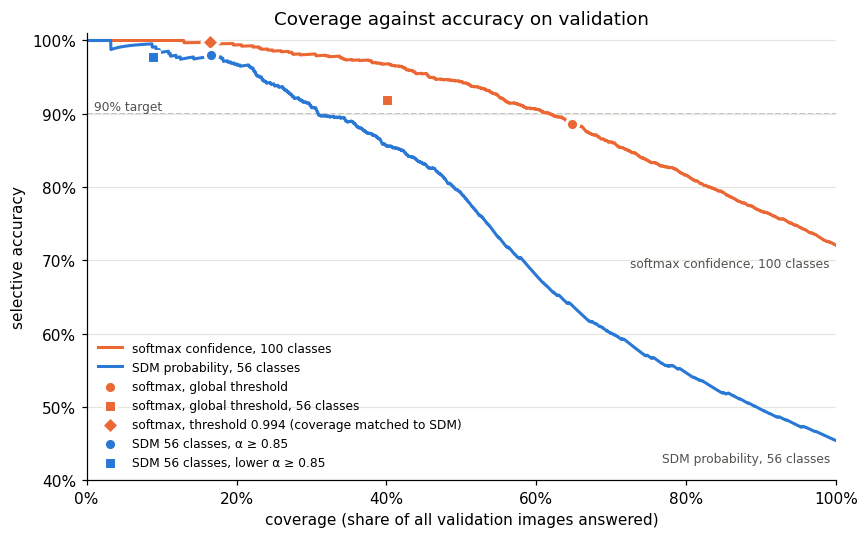

In [14]:
SOFTMAX_COLOR, SDM_COLOR = "#eb6834", "#2a78d6"  # categorical slots 2 and 1 of the reference palette


def coverage_accuracy_curve(score, correct):
    order = np.argsort(-score)
    answered = np.arange(1, len(order) + 1)
    return answered / len(order), np.cumsum(correct[order]) / answered


fig, ax = plt.subplots(figsize=(8, 5))
curves = [("softmax confidence, 100 classes", val_conf, val_pred, SOFTMAX_COLOR),
          (f"SDM probability, {len(selected_strict)} classes", *sdm_rule(run_strict, 0)[2:0:-1], SDM_COLOR)]
for label, score, prediction, color in curves:
    coverage, accuracy = coverage_accuracy_curve(score, prediction == y_val)
    ax.plot(coverage, accuracy, color=color, linewidth=2, label=label)
    ax.annotate(label, (coverage[-1], accuracy[-1]), xytext=(-4, -14), textcoords="offset points",
                ha="right", fontsize=8, color="#52514e")

points = [("softmax, global threshold", SOFTMAX_COLOR, "o"),
          (f"softmax, global threshold, {len(selected_strict)} classes", SOFTMAX_COLOR, "s"),
          (f"softmax, threshold {matched_threshold:.3f} (coverage matched to SDM)", SOFTMAX_COLOR, "D"),
          (f"SDM {len(selected_strict)} classes, α ≥ {top_alpha(run_strict):.2f}", SDM_COLOR, "o"),
          (f"SDM {len(selected_strict)} classes, lower α ≥ {top_alpha(run_strict):.2f}", SDM_COLOR, "s")]
for rule, color, marker in points:
    admit, prediction, _, _ = rules[rule]
    ax.scatter(admit.mean(), (prediction == y_val)[admit].mean(), s=64, color=color, marker=marker,
               edgecolor="white", linewidth=2, zorder=3, label=rule)

ax.axhline(0.90, color="#b0afa9", linewidth=1, linestyle="--", zorder=0)
ax.text(0.01, 0.905, "90% target", fontsize=8, color="#52514e", transform=ax.get_yaxis_transform())
ax.set(xlabel="coverage (share of all validation images answered)", ylabel="selective accuracy",
       xlim=(0, 1), ylim=(0.4, 1.01), title="Coverage against accuracy on validation")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.legend(fontsize=8, frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

### What the metrics say

Numbers below are from our run; rerunning with a different checkpoint will change them.

1. **Restricting to well-handled classes and using SDM gives high accuracy at low coverage.** SDM on the 56 classes at α ≥ 0.85 answers about 17% of all validation images at about 98% accuracy, and answers only a handful of excluded-class images.
2. **But a plain softmax threshold does at least as well at the same coverage.** With its threshold raised to match SDM's coverage (about 0.99 confidence), the 100-class softmax answers the same share of images at higher accuracy (99.8% against 98.1%), answers no excluded-class images by construction, and its worst class is better (83% against 67%). Its coverage-accuracy curve lies above SDM's at every coverage level, and its AURC is much lower. SDM's AUROC is slightly higher, but that is partly because SDM makes more mistakes overall (it cannot predict the excluded classes), and those are easy to rank low.
3. **So on this ResNet, SDM's advantage is not better ranking.** What SDM adds is a **per-class promise set on calibration data** (every class at α or above inside the region) and rejection of images unlike the training images. The softmax threshold only promises an overall average, even though here, at high confidence, its per-class precision happens to be good.
4. **Why softmax is so strong here:** the ResNet nearly memorized its training images, so SDM's similarity signal (do the nearest training images agree?) carries little information that the softmax confidence does not already have. SDM's region rule is also deliberately conservative (α = 0.85 while validation accuracy is about 98%), which costs coverage.
5. **Caveats.** Validation has 25 images per class, so per-class numbers are noisy. SDM's α was calibrated on the same images that chose the classes. The matched softmax threshold uses SDM's validation coverage only to pick a coverage level; the threshold itself comes from calibration.

**Takeaway:** if the goal is "≥ 90% accuracy on the images we answer", a high softmax threshold already reaches it on all 100 classes. SDM is worth it when the requirement is a **per-class** guarantee, or protection against images from classes the model was not built for.